# L15 worked example: Bayesian optimization of a reactor

A raw material A turns into the product B in a stirred tank. B keeps reacting into a waste, C.
Heat speeds up both steps, but the second one more. Too cold, and A barely reacts. Too hot, and
B burns into C.

**The question:** which temperature gives the most B, using as few experiments as possible?

Each experiment costs hours of lab time, so we let a Gaussian process (GP) choose the next one:
Bayesian optimization (BO), in [BoTorch](https://botorch.org).

## Run this first on Colab

Colab starts from its own preinstalled environment rather than this course's `uv`
environment, so run the cell below before anything else. It installs what this
notebook needs and Colab does not already have. Outside Colab it does nothing, so
you can run it or skip it.


In [ ]:
# Run this first on Colab. Anywhere else this cell does nothing.
#
# Only genuinely missing packages are installed, so Colab's own versions of
# everything it already ships are left alone.
import importlib.util
import subprocess
import sys

REQUIREMENTS = {
    "botorch": "botorch",
    "gpytorch": "gpytorch",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "torch": "torch",
}


def _missing(module):
    try:
        return importlib.util.find_spec(module) is None
    except ModuleNotFoundError:  # the parent package is absent
        return True


if "google.colab" in sys.modules:
    need = sorted({pip for mod, pip in REQUIREMENTS.items() if _missing(mod)})
    if need:
        print("installing:", " ".join(need))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    print("Colab setup done." if need else "Colab: nothing to install.")


## 1. Libraries

- [BoTorch](https://botorch.org): Bayesian optimization on PyTorch.
- [GPyTorch](https://gpytorch.ai): the Gaussian processes BoTorch uses.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from botorch.acquisition import LogExpectedImprovement
from botorch.fit import fit_gpytorch_mll
from botorch.models import SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.optim import optimize_acqf
from gpytorch.mlls import ExactMarginalLogLikelihood

torch.set_default_dtype(torch.float64)

/Users/victoralves/.cache/uv/archive-v0/Joy0w0OcCXEIsbA3/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. The experiment

At steady state, the fraction of A that leaves the tank as B (the **yield**) is

$$
y = \frac{k_1 \tau}{(1 + k_1 \tau)(1 + k_2 \tau)}
$$

- $k_1$, $k_2$: the rate constants of A → B and B → C (1/min), from Arrhenius' law.
- $\tau$: the residence time, how long the liquid stays in the tank (min).

In the lab nobody has this formula: an experiment returns one measured yield, with noise. We
use the formula only to play the role of the lab, and to check the answer at the end.

In [3]:
R = 8.314                     # J/(mol K)


def rate(T, k_ref, E):
    # Arrhenius: rate constant (1/min) at T (degC), relative to 80 degC
    T = T + 273.15
    return k_ref * np.exp(-E / R * (1 / T - 1 / 353.15))


def yield_B(T, tau):
    # steady-state yield of B in the tank, for A -> B -> C
    k1 = rate(T, 0.15, 60e3)      # A -> B
    k2 = rate(T, 0.03, 110e3)     # B -> C: needs more heat
    return k1 * tau / ((1 + k1 * tau) * (1 + k2 * tau))


rng = np.random.default_rng(0)


def run_experiment(T):
    # one experiment per row of T (degC): 10 min in the tank, noise 0.01
    y = yield_B(T.numpy().ravel(), 10.0)
    y = y + 0.01 * rng.standard_normal(T.shape[0])
    return torch.tensor(y).unsqueeze(-1)

## 3. Two old runs

The lab notebook has two runs, both on the cold side: 30 °C and 50 °C.

In [4]:
bounds = torch.tensor([[20.0], [140.0]])      # temperature from 20 to 140 degC
torch.manual_seed(0)

# two old runs from the lab notebook
T = torch.tensor([[30.0], [50.0]])
y = run_experiment(T)

## 4. The loop

Each pass:

1. Fit a GP to every experiment so far: the **surrogate**.
2. Score every temperature with **expected improvement**: how much it is expected to beat the
   best yield so far.
3. Run the experiment where that score is largest, and add it to the data.

In [5]:
for i in range(10):
    # 1. the surrogate: a GP fitted to every experiment so far
    gp = SingleTaskGP(
        T,
        y,
        input_transform=Normalize(d=1),
        outcome_transform=Standardize(m=1),
    )
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)

    # 2. the acquisition: expected improvement over the best yield so far
    acq = LogExpectedImprovement(gp, best_f=y.max())

    # 3. the next experiment: where the acquisition is largest
    T_next, _ = optimize_acqf(
        acq,
        bounds=bounds,
        q=1,
        num_restarts=10,
        raw_samples=200,
    )

    # 4. run it, and add it to the data
    y_next = run_experiment(T_next)
    T = torch.cat([T, T_next])
    y = torch.cat([y, y_next])

In [6]:
for k in range(len(y)):
    print(f"experiment {k + 1:2d}: T = {T[k].item():5.1f} C, yield {y[k].item():.3f}")

experiment  1: T =  30.0 C, yield 0.050
experiment  2: T =  50.0 C, yield 0.181
experiment  3: T =  54.4 C, yield 0.236
experiment  4: T =  60.7 C, yield 0.306
experiment  5: T =  71.5 C, yield 0.419
experiment  6: T =  86.9 C, yield 0.430
experiment  7: T =  80.5 C, yield 0.474
experiment  8: T = 140.0 C, yield 0.023
experiment  9: T =  80.0 C, yield 0.454
experiment 10: T =  80.0 C, yield 0.449
experiment 11: T =  80.1 C, yield 0.455
experiment 12: T = 102.5 C, yield 0.219


## 5. Check the answer

Only here do we look at the true curve, which the optimizer never saw.

best experiment: T = 80.5 C, measured yield 0.474
true yield there: 0.461
true best: T = 79.5 C, yield 0.462


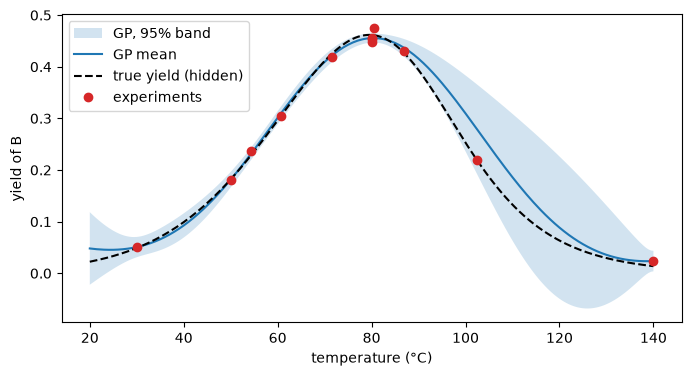

In [7]:
k = int(y.argmax())
print(f"best experiment: T = {T[k].item():.1f} C, measured yield {y[k].item():.3f}")
print(f"true yield there: {yield_B(T[k].item(), 10.0):.3f}")

T_grid = np.linspace(20, 140, 241)
print(f"true best: T = {T_grid[yield_B(T_grid, 10.0).argmax()]:.1f} C, yield {yield_B(T_grid, 10.0).max():.3f}")

with torch.no_grad():
    post = gp.posterior(torch.tensor(T_grid).unsqueeze(-1))
    mu = post.mean.squeeze().numpy()
    sd = post.variance.sqrt().squeeze().numpy()

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(
    T_grid,
    mu - 1.96 * sd,
    mu + 1.96 * sd,
    alpha=0.2,
    label="GP, 95% band",
)
ax.plot(T_grid, mu, label="GP mean")
ax.plot(
    T_grid,
    yield_B(T_grid, 10.0),
    "k--",
    label="true yield (hidden)",
)
ax.plot(T.numpy(), y.numpy(), "o", color="C3", label="experiments")
ax.set_xlabel("temperature (°C)")
ax.set_ylabel("yield of B")
ax.legend()
plt.show()

## 6. Two knobs: temperature and residence time

Now the pump flow sets the residence time too, from 1 to 30 min. Same loop, two inputs. We
compare it with random search, five seeds each, and report the true yield of the best
experiment so far.

In [8]:
bounds2 = torch.tensor([[20.0, 1.0], [140.0, 30.0]])    # T (degC), tau (min)


def run_experiment2(X, rng):
    # one experiment per row of X = [T, tau]
    y = yield_B(X[:, 0].numpy(), X[:, 1].numpy()) + 0.01 * rng.standard_normal(X.shape[0])
    return torch.tensor(y).unsqueeze(-1)


def bo_campaign(seed, n_total=30):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    X = torch.tensor([[30.0, 5.0], [50.0, 10.0], [40.0, 20.0]])    # three old runs
    y = run_experiment2(X, rng)
    while len(y) < n_total:
        gp = SingleTaskGP(
            X,
            y,
            input_transform=Normalize(d=2),
            outcome_transform=Standardize(m=1),
        )
        mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
        fit_gpytorch_mll(mll)
        acq = LogExpectedImprovement(gp, best_f=y.max())
        x_next, _ = optimize_acqf(
            acq,
            bounds=bounds2,
            q=1,
            num_restarts=10,
            raw_samples=256,
        )
        X = torch.cat([X, x_next])
        y = torch.cat([y, run_experiment2(x_next, rng)])
    return X.numpy(), y.numpy().ravel()


def random_campaign(seed, n_total=30):
    rng = np.random.default_rng(2000 + seed)
    X = torch.tensor(rng.uniform([20.0, 1.0], [140.0, 30.0], size=(n_total, 2)))
    return X.numpy(), run_experiment2(X, rng).numpy().ravel()


def best_so_far(X, y):
    # the true yield of the experiment that looks best so far
    return [yield_B(*X[np.argmax(y[:n])]) for n in range(1, len(y) + 1)]


bo_runs = [best_so_far(*bo_campaign(seed)) for seed in range(5)]
random_runs = [best_so_far(*random_campaign(seed)) for seed in range(5)]

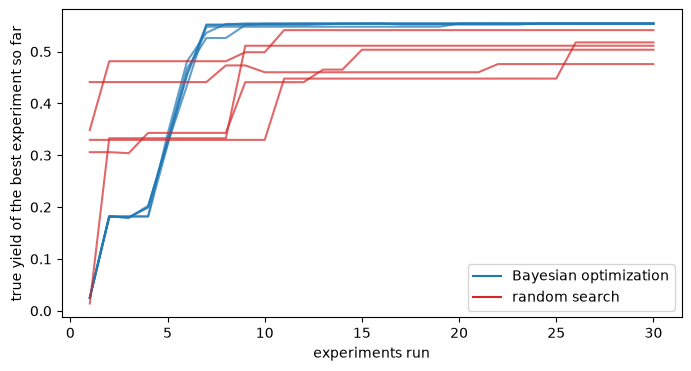

BO: after 30 experiments, best yield 0.554 to 0.554
random: after 30 experiments, best yield 0.476 to 0.541


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for run in bo_runs:
    ax.plot(range(1, 31), run, color="C0", alpha=0.7)
for run in random_runs:
    ax.plot(range(1, 31), run, color="C3", alpha=0.7)
ax.plot([], [], color="C0", label="Bayesian optimization")
ax.plot([], [], color="C3", label="random search")
ax.set_xlabel("experiments run")
ax.set_ylabel("true yield of the best experiment so far")
ax.legend()
plt.show()

for name, runs in [("BO", bo_runs), ("random", random_runs)]:
    final = [run[-1] for run in runs]
    print(f"{name}: after 30 experiments, best yield {np.min(final):.3f} to {np.max(final):.3f}")

## Try it

- Replace `LogExpectedImprovement(gp, best_f=y.max())` with
  `UpperConfidenceBound(gp, beta=4.0)` (import it from `botorch.acquisition`). BoTorch's
  `beta` is $\kappa^2$, so this is $\mu + 2\sigma$. Does it explore more?
- Start the 1-D loop from a single run at 30 °C. How many experiments does it need now?
- Raise the noise from 0.01 to 0.05. What happens to the GP's band, and to the picks?